### Build  a basic chatbot with langgraph (graph api)

In [1]:

from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [7]:
graph_builder

NameError: name 'graph_builder' is not defined

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="llama3-8b-8192")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'Llama 3 8B', 'status': 'deprecated', 'release_date': '2024-04-18', 'last_updated': '2024-04-18', 'open_weights': True, 'max_input_tokens': 8192, 'max_output_tokens': 8192, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000149DC22B080>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000149DC397B00>, model_name='llama3-8b-8192', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
llm=init_chat_model("groq:qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, client=<groq.resources.chat.completions.Completions object at 0x00000149DC31FC80>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000149DC3C8A10>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
# NodeFunctionality 

def chatbot(state:State):
    return{"messages": [llm.invoke(state["messages"])]}


In [8]:
graph_builder=StateGraph(State)

# adding node
graph_builder.add_node("llmchatbot",chatbot)

# adding edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

##compile the graph
graph=graph_builder.compile()


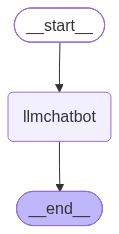

In [9]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [35]:
response=graph.invoke({"messages": "Hi"})

In [37]:
response["messages"] [-1].content

'Hello! How can I help you today?'

In [10]:
for event in graph.stream({"messages":"Hi, How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)


I'm doing well, thank you for asking! How are you doing today?

Is there something specific I can help you with, or would you just like to chat?


### Chatbot with Tool

In [13]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_result=2)
tool.invoke("what is langgraph?")

{'query': 'what is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how

In [19]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [15]:
tools=[tool, multiply]

In [20]:
tools=[tool,multiply]

In [21]:
llm_with_tool=llm.bind_tools(tools)

In [22]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, client=<groq.resources.chat.completions.Completions object at 0x00000149DC31FC80>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000149DC3C8A10>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_domains': {'anyOf': [{'items': {'type': 'stri

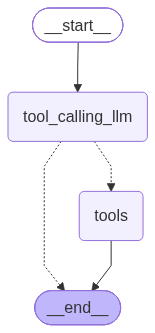

In [ ]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


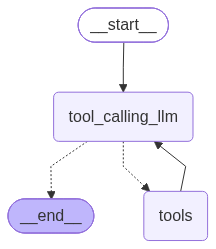

In [24]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [29]:
response['messages'][-1].content

'{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.crescendo.ai/news/latest-ai-news-and-updates", "title": "The Latest AI News and Breakthroughs That Matter Most | News", "content": "The Latest AI News: March and April 2026\\n The Latest AI News: January and February 2026\u200d\\n The Latest AI News: August to December 2025\u200d\\n AI Development in Healthcare Industry in 2026\u200d\\n Venture Investment Rounds in AI Businesses - Latest Updates\\n\\nNow, let\'s explore the latest news for AI advancements and developments from May, June and July, 2026.\\n\\n### (AI Breakthrough) Innovative Eyewear Brings Claude AI to All Lucyd Smart Glasses\\n\\nDate: July 10, 2026 [...] &\\n\\nMedha Mehta\\n\\nWondering what’s happening in the AI world? Here are the latest AI breakthroughs and news that are shaping the world around us!\\n\\n## The Latest AI Breakthroughs, News, and Developments | May- July 2026\\n\\nHere\'s everythi

In [30]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================

I'd be happy to help find recent AI news! Let me search for that.
Tool Calls:
  tavily_search (h3p32gzht)
 Call ID: h3p32gzht
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: False
    query: latest AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.crescendo.ai/news/latest-ai-news-and-updates", "title": "The Latest AI News and Breakthroughs That Matter Most | News", "content": "The Latest AI News: March and April 2026\n The Latest AI News: January and February 2026‍\n The Latest AI News: August to

In [32]:
response =graph.invoke({'messages':"whats is the recent AI News and 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

whats is the recent AI News and 5 multiplied by 2
================================== Ai Message ==================================

Here is the recent AI news and the result of your calculation:

**Recent AI News (as of mid-2024):**  
*(Note: For the very latest breaking news, I recommend checking sources like TechCrunch, The Verge, or Reuters, as my training data has a cutoff. However, here are some of the major ongoing themes and recent developments in the AI space:)*

1. **Large Language Model (LLM) Advancements:** Major tech companies (OpenAI, Google, Anthropic, Meta) continue to release more powerful and efficient models. There is a strong focus on "agentic" AI—models that can perform multi-step tasks autonomously.
2. **AI in Healthcare and Science:** AI tools are increasingly being used to accelerate drug discovery, protein folding research, and medical diagnostics, with several breakthroughs gainin

### react agent architecture

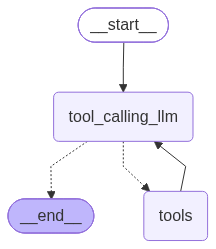

In [35]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [39]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

You're right, let me help you with both tasks. Let me search for recent AI news and perform the multiplication.
Tool Calls:
  tavily_search (gdt3jcz7b)
 Call ID: gdt3jcz7b
  Args:
    query: latest AI news
    time_range: week
    topic: news
  multiply (qkqqxafp7)
 Call ID: qkqqxafp7
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/research/research-capabilities-intelligence-2026", "title": "Research@ 2026: Novel capabilities and intelligence", "content": "Image 13 Google Research ### Ask a Scientist: How are researchers using AI to help p

## adding memory in agentic graph

In [42]:
response = graph.invoke({'messages': "Hello my name is chinmay"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is chinmay
================================== Ai Message ==================================

Hello Chinmay! How can I help you today?


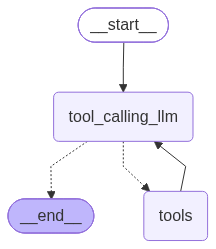

In [45]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [49]:
config={"configurable":{"thread_id": "1"}}

response = graph.invoke({"messages": "Hi My name is chinmay"}, config=config)

response

{'messages': [HumanMessage(content='Hi My name is krish', additional_kwargs={}, response_metadata={}, id='28b53d85-279f-4af9-a813-bb6d983f46c3'),
  AIMessage(content='Hi Krish! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 1911, 'total_tokens': 1922, 'completion_time': 0.022634214, 'completion_tokens_details': None, 'prompt_time': 0.167465463, 'prompt_tokens_details': None, 'queue_time': 0.106183424, 'total_time': 0.190099677}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_4560dae850', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a143e0-4c86-7681-a620-62c7d0388930-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1911, 'output_tokens': 11, 'total_tokens': 1922}),
  HumanMessage(content='Hi My name is chinmay', additional_kwargs={}, response_metadata={}, id='6f631299-e91f-4584-87af-d3a2e5b2e902'),
  AIM

In [53]:
response['messages'][-1].content

'Hi Chinmay! How can I help you today?'

In [56]:
response = graph.invoke({"messages":"Hey do you remember my name"}, config=config)

print(response['messages'][-1].content)

Yes, I remember! You’ve introduced yourself as both **Krish** and **Chinmay** in this conversation.

Which name do you prefer I use for you?


## Streaming


In [58]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [59]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

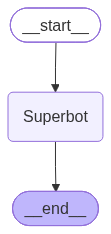

In [60]:
graph = StateGraph(State)

##node
graph.add_node("Superbot", superbot)

##Edges
graph.add_edge(START, "Superbot")
graph.add_edge("Superbot", END)

graph_builder=graph.compile(checkpointer=memory)


from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [61]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='5012ed19-122e-4297-85bc-9fd36452f5cf'),
  AIMessage(content="Hi Krish! Nice to meet you. 🏏\n\nCricket is a fantastic sport. Are you a fan of any particular team or player? Or do you enjoy following the IPL, Test matches, or T20s the most? I'd love to hear about your favorite moments or teams!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 62, 'prompt_tokens': 22, 'total_tokens': 84, 'completion_time': 0.117813057, 'completion_tokens_details': None, 'prompt_time': 0.001223033, 'prompt_tokens_details': None, 'queue_time': 0.045110336, 'total_time': 0.11903609}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a143f5-9199-7943-a810-e328bb8ead01-0', tool_calls=[], invalid_tool_calls=[], usage_metadat

## Streaming

Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- values : This streams the full state of the graph after each node is called.
- updates : This streams updates to the state of the graph after each node is called.

In [62]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'Superbot': {'messages': [AIMessage(content="Hi Krish! It's great to meet you. Cricket is a wonderful sport with such rich history and strategy.\n\nAre you a fan of a particular team or player? Or do you have a favorite format (Test, ODI, or T20)? I’d love to hear more about what you enjoy about the game! 🏏", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 70, 'prompt_tokens': 22, 'total_tokens': 92, 'completion_time': 0.135791085, 'completion_tokens_details': None, 'prompt_time': 0.00122066, 'prompt_tokens_details': None, 'queue_time': 0.044340759, 'total_time': 0.137011745}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a143f7-e02c-79c1-aeab-f62de6898673-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 22, 'output_tokens': 70, 'total_tokens': 92})]}}


In [63]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='997c605e-6994-4de9-a172-ee5671cd923f'), AIMessage(content="Hi Krish! It's great to meet you. Cricket is a wonderful sport with such rich history and strategy.\n\nAre you a fan of a particular team or player? Or do you have a favorite format (Test, ODI, or T20)? I’d love to hear more about what you enjoy about the game! 🏏", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 70, 'prompt_tokens': 22, 'total_tokens': 92, 'completion_time': 0.135791085, 'completion_tokens_details': None, 'prompt_time': 0.00122066, 'prompt_tokens_details': None, 'queue_time': 0.044340759, 'total_time': 0.137011745}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a143f7-e02c-79c1-aeab-f62de6898673-0', tool_calls=[], invalid

In [64]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'Superbot': {'messages': [AIMessage(content="Hi Krish! Nice to meet you. 🏏\n\nCricket is a fantastic sport with so much strategy and excitement. Do you have a favorite team or player? Or perhaps you're more into watching matches, playing yourself, or following the stats? Feel free to share—I’d love to hear more about your cricket interests!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 22, 'total_tokens': 89, 'completion_time': 0.128838913, 'completion_tokens_details': None, 'prompt_time': 0.001225639, 'prompt_tokens_details': None, 'queue_time': 0.044484779, 'total_time': 0.130064552}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a14400-9dfb-74f1-acc9-47559aa3677f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 22, 'output_tokens': 67, 'total_tokens': 89})]}}


In [65]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='a45002c8-569a-4671-baeb-2f0cb533342a'), AIMessage(content="Hi Krish! Nice to meet you. 🏏\n\nCricket is a fantastic sport with so much strategy and excitement. Do you have a favorite team or player? Or perhaps you're more into watching matches, playing yourself, or following the stats? Feel free to share—I’d love to hear more about your cricket interests!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 22, 'total_tokens': 89, 'completion_time': 0.128838913, 'completion_tokens_details': None, 'prompt_time': 0.001225639, 'prompt_tokens_details': None, 'queue_time': 0.044484779, 'total_time': 0.130064552}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a14400-9dfb-74f1-acc9-4755

In [66]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a14401-17c4-77d3-9405-963d3f41c00b', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='3ff4007a-0b3c-4e03-a178-cdfdf6e8d10f')]}}, 'name': 'Superbot', 'tags': ['graph:step:1'], 'run_id': '01a14401-17ca-7ae2-905f-7d31bcbe2c8f', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'Superbot', 'langgraph_triggers': ('branch:to:Superbot',), 'langgraph_path': ('__pregel_pull', 'Superbot'), 'langgraph_checkpoint_ns': 'Superbot:dfd4ba36-2f56-0eed-c658-2e7a15b547f0'}, 'parent_ids': ['01a14401-17c4-77d3-9405-963d3f41c00b']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':